In [111]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


from pathlib import Path
print("Libraries imported successfully")

Libraries imported successfully


In [112]:
from pathlib import Path

PROJECT_ROOT = Path("..")

DATASET_DIR = PROJECT_ROOT / "datasets" / "Celeb-DF-v2"

print("Dataset path:")
print(DATASET_DIR)

print("\nExists:", DATASET_DIR.exists())

Dataset path:
..\datasets\Celeb-DF-v2

Exists: True


In [113]:
for item in DATASET_DIR.iterdir():
    print(item.name)

Celeb-real
Celeb-synthesis
List_of_testing_videos.txt
YouTube-real


In [114]:
#  all-video-count

video_extensions = {".mp4", ".avi", ".mov", ".mkv"}

video_files = []

for file in DATASET_DIR.rglob("*"):
    if file.is_file() and file.suffix.lower() in video_extensions:
        video_files.append(file)

print("Total video files:", len(video_files))

Total video files: 6529


In [115]:
for video in video_files[:10]:
    print(video)

..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0005.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0006.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0007.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0008.mp4
..\datasets\Celeb-DF-v2\Celeb-real\id0_0009.mp4


# real or fake identity

In [116]:
for item in DATASET_DIR.iterdir():

    if item.is_dir():
        print(
            item.name,
            "->",
            len([
                f for f in item.rglob("*")
                if f.suffix.lower() in video_extensions
            ]),
            "videos"
        )

Celeb-real -> 590 videos
Celeb-synthesis -> 5639 videos
YouTube-real -> 300 videos


In [117]:
for item in DATASET_DIR.iterdir():

    if item.is_dir():
        print(
            item.name,
            "->",
            len([
                f for f in item.rglob("*")
                if f.suffix.lower() in video_extensions
            ]),
            "videos"
        )

Celeb-real -> 590 videos
Celeb-synthesis -> 5639 videos
YouTube-real -> 300 videos


In [118]:
# dataset information

records = []

for video in video_files:

    records.append({
        "video_path": str(video),
        "filename": video.name,
        "extension": video.suffix,
        "parent_folder": video.parent.name
    })

df = pd.DataFrame(records)

df.head()


,video_path,filename,extension,parent_folder
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,.mp4,Celeb-real
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,.mp4,Celeb-real
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,.mp4,Celeb-real
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,.mp4,Celeb-real
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,.mp4,Celeb-real


In [119]:
print("Total videos:", len(df))

print("\nVideos by folder:")
print(df["parent_folder"].value_counts())

Total videos: 6529

Videos by folder:
parent_folder
Celeb-synthesis    5639
Celeb-real          590
YouTube-real        300
Name: count, dtype: int64


In [120]:
def get_label(folder_name):

    folder_name = folder_name.lower()

    if "real" in folder_name:
        return 0

    elif "synthesis" in folder_name:
        return 1

    return -1


df["label"] = df["parent_folder"].apply(get_label)

df.head()

,video_path,filename,extension,parent_folder,label
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,.mp4,Celeb-real,0
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,.mp4,Celeb-real,0
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,.mp4,Celeb-real,0
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,.mp4,Celeb-real,0
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,.mp4,Celeb-real,0


In [121]:
print(df["label"].value_counts())

label
1    5639
0     890
Name: count, dtype: int64


# LABEL DISTRIBUTION

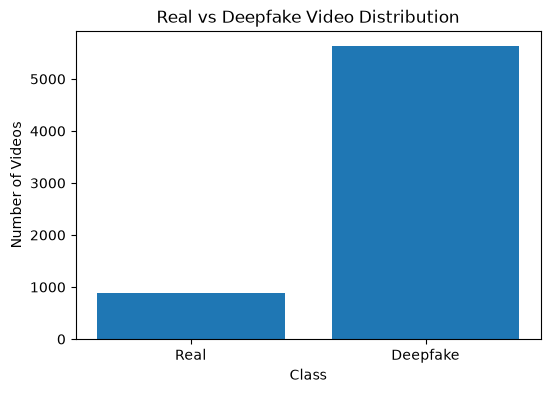

In [122]:
label_counts = df["label"].value_counts().sort_index()

plt.figure(figsize=(6, 4))

plt.bar(
    ["Real", "Deepfake"],
    [
        label_counts.get(0, 0),
        label_counts.get(1, 0)
    ]
)

plt.title("Real vs Deepfake Video Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Videos")

plt.show()

In [123]:
#check 1 video
sample_video = video_files[0]

cap = cv2.VideoCapture(str(sample_video))

if not cap.isOpened():
    print("Error: Could not open video")
else:
    print("Video opened successfully!")

Video opened successfully!


In [124]:
#video properties

fps = cap.get(cv2.CAP_PROP_FPS)
frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

duration = frame_count / fps if fps > 0 else 0

print("Video:", sample_video.name)
print("FPS:", fps)
print("Total frames:", int(frame_count))
print("Width:", int(width))
print("Height:", int(height))
print("Duration:", round(duration, 2), "seconds")

Video: id0_0000.mp4
FPS: 30.0
Total frames: 469
Width: 942
Height: 500
Duration: 15.63 seconds


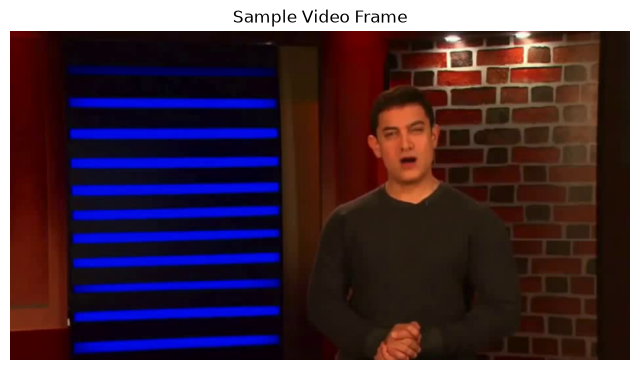

In [125]:
# 1st Frame display

cap.set(cv2.CAP_PROP_POS_FRAMES, 0)

ret, frame = cap.read()

if ret:

    frame_rgb = cv2.cvtColor(
        frame,
        cv2.COLOR_BGR2RGB
    )

    plt.figure(figsize=(8, 5))
    plt.imshow(frame_rgb)
    plt.axis("off")
    plt.title("Sample Video Frame")
    plt.show()

else:
    print("Could not read frame.")

cap.release()

In [126]:
def assign_label(folder_name):
    folder_name = folder_name.lower()

    if "synthesis" in folder_name:
        return 1

    elif "real" in folder_name:
        return 0

    else:
        return -1


label_names = {
    0: "Real",
    1: "Deepfake",
    -1: "Unknown"
}

print("Label function created successfully!")

Label function created successfully!


# day 2

In [127]:
folder_counts = {}

for video in video_files:
    folder = video.parent.name

    if folder not in folder_counts:
        folder_counts[folder] = 0

    folder_counts[folder] += 1

folder_counts_df = pd.DataFrame(
    list(folder_counts.items()),
    columns=["Folder", "Video_Count"]
)

folder_counts_df = folder_counts_df.sort_values(
    "Video_Count",
    ascending=False
)

display(folder_counts_df)

,Folder,Video_Count
1,Celeb-synthesis,5639
0,Celeb-real,590
2,YouTube-real,300


In [128]:
print("Label counts:")
print(df["label"].value_counts())




Label counts:
label
1    5639
0     890
Name: count, dtype: int64


In [129]:
label_names = {
    0: "Real",
    1: "Deepfake",
    -1: "Unknown"
}

df["class_name"] = df["label"].map(label_names)

print(df["class_name"].value_counts())

class_name
Deepfake    5639
Real         890
Name: count, dtype: int64


In [130]:
# class distribution percentage 
class_distribution = (
    df["class_name"]
    .value_counts()
    .to_frame("Count")
)

class_distribution["Percentage"] = (
    class_distribution["Count"]
    / class_distribution["Count"].sum()
    * 100
)

display(class_distribution)

,Count,Percentage
class_name,,
Deepfake,5639,86.36851
Real,890,13.63149


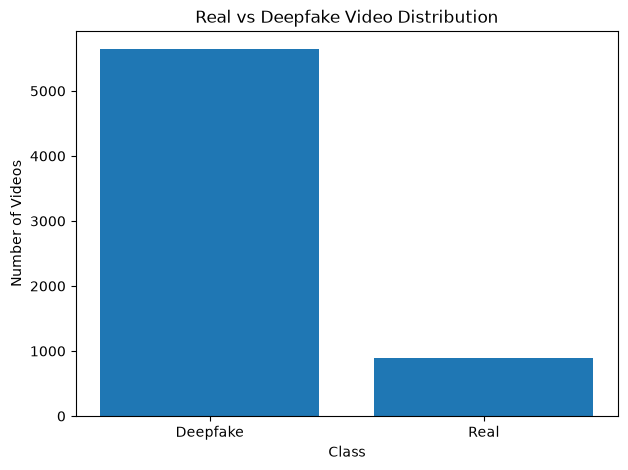

In [131]:
plt.figure(figsize=(7, 5))

class_counts = df["class_name"].value_counts()

plt.bar(
    class_counts.index,
    class_counts.values
)

plt.title("Real vs Deepfake Video Distribution")
plt.xlabel("Class")
plt.ylabel("Number of Videos")

plt.show()

In [132]:
# video mmeta-data
video_metadata = []

for i, video_path in enumerate(video_files):

    cap = cv2.VideoCapture(str(video_path))

    fps = cap.get(cv2.CAP_PROP_FPS)
    frame_count = cap.get(cv2.CAP_PROP_FRAME_COUNT)
    width = cap.get(cv2.CAP_PROP_FRAME_WIDTH)
    height = cap.get(cv2.CAP_PROP_FRAME_HEIGHT)

    duration = (
        frame_count / fps
        if fps > 0
        else 0
    )

    video_metadata.append({
        "video_path": str(video_path),
        "filename": video_path.name,
        "folder": video_path.parent.name,
        "fps": fps,
        "frame_count": frame_count,
        "width": width,
        "height": height,
        "duration": duration
    })

    cap.release()

    if (i + 1) % 100 == 0:
        print(f"Processed {i + 1}/{len(video_files)} videos")

video_metadata_df = pd.DataFrame(video_metadata)

print("Metadata collection completed!")

display(video_metadata_df.head())

Processed 100/6529 videos
Processed 200/6529 videos
Processed 300/6529 videos
Processed 400/6529 videos
Processed 500/6529 videos
Processed 600/6529 videos
Processed 700/6529 videos
Processed 800/6529 videos
Processed 900/6529 videos
Processed 1000/6529 videos
Processed 1100/6529 videos
Processed 1200/6529 videos
Processed 1300/6529 videos
Processed 1400/6529 videos
Processed 1500/6529 videos
Processed 1600/6529 videos
Processed 1700/6529 videos
Processed 1800/6529 videos
Processed 1900/6529 videos
Processed 2000/6529 videos
Processed 2100/6529 videos
Processed 2200/6529 videos
Processed 2300/6529 videos
Processed 2400/6529 videos
Processed 2500/6529 videos
Processed 2600/6529 videos
Processed 2700/6529 videos
Processed 2800/6529 videos
Processed 2900/6529 videos
Processed 3000/6529 videos
Processed 3100/6529 videos
Processed 3200/6529 videos
Processed 3300/6529 videos
Processed 3400/6529 videos
Processed 3500/6529 videos
Processed 3600/6529 videos
Processed 3700/6529 videos
Processed 

,video_path,filename,folder,fps,frame_count,width,height,duration
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667


In [133]:
# add label meta data
video_metadata_df["label"] = video_metadata_df["folder"].apply(assign_label
)

video_metadata_df["class_name"] = (
    video_metadata_df["label"].map(label_names)
)

display(video_metadata_df.head())


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333,0,Real
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000,0,Real
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667,0,Real
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333,0,Real
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667,0,Real


In [134]:
video_metadata_df[
    [
        "fps",
        "frame_count",
        "width",
        "height",
        "duration"
    ]
].describe()

,fps,frame_count,width,height,duration
count,6529.000000,6529.000000,6529.000000,6529.000000,6529.000000
mean,29.989732,379.163425,813.769643,480.456425,12.643340
std,0.081835,84.870207,125.586198,20.719591,2.831243
min,28.756999,1.000000,286.000000,298.000000,0.033333
25%,30.000000,317.000000,842.000000,472.000000,10.566667
50%,30.000000,349.000000,850.000000,478.000000,11.633333
75%,30.000000,458.000000,856.000000,500.000000,15.266667
max,30.000000,740.000000,974.000000,500.000000,24.666667


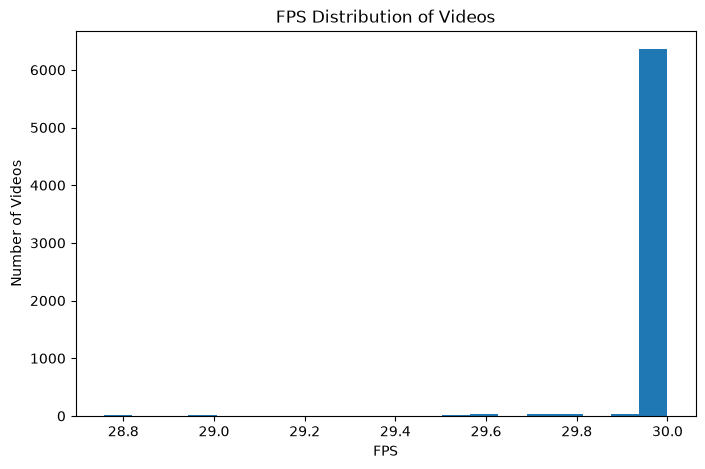

In [135]:
plt.figure(figsize=(8, 5))

plt.hist(
    video_metadata_df["fps"],
    bins=20
)

plt.title("FPS Distribution of Videos")
plt.xlabel("FPS")
plt.ylabel("Number of Videos")

plt.show()

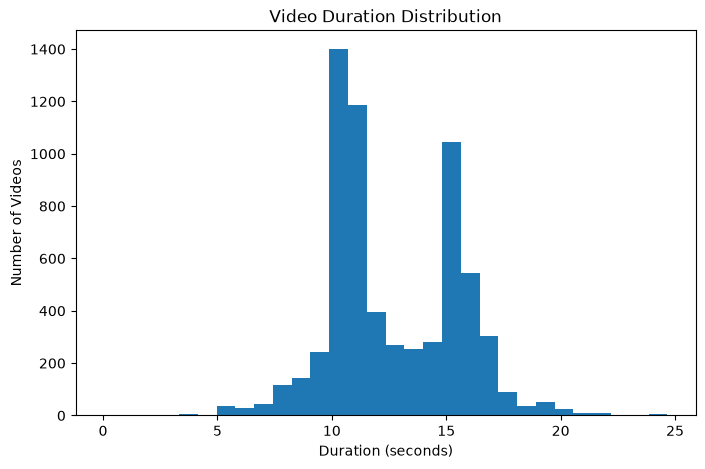

In [136]:
plt.figure(figsize=(8, 5))

plt.hist(
    video_metadata_df["duration"],
    bins=30
)

plt.title("Video Duration Distribution")
plt.xlabel("Duration (seconds)")
plt.ylabel("Number of Videos")

plt.show()

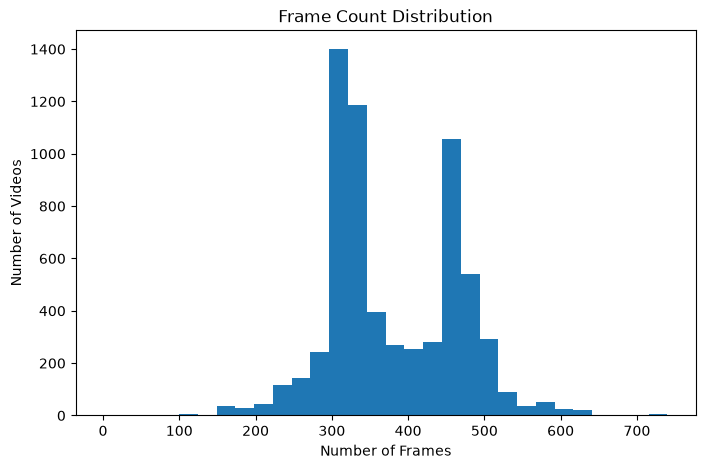

In [137]:
plt.figure(figsize=(8, 5))

plt.hist(
    video_metadata_df["frame_count"],
    bins=30
)

plt.title("Frame Count Distribution")
plt.xlabel("Number of Frames")
plt.ylabel("Number of Videos")

plt.show()

In [138]:
video_metadata_df["resolution"] = (
    video_metadata_df["width"].astype(int).astype(str)
    + "x"
    + video_metadata_df["height"].astype(int).astype(str)
)

resolution_counts = (
    video_metadata_df["resolution"]
    .value_counts()
)

display(resolution_counts.head(15))

resolution
856x478    1251
944x500     604
850x472     520
848x466     475
848x472     239
892x500     199
950x500     183
846x476     169
852x480     169
846x474     156
844x474      96
834x458      95
812x456      93
850x476      83
848x478      83
Name: count, dtype: int64

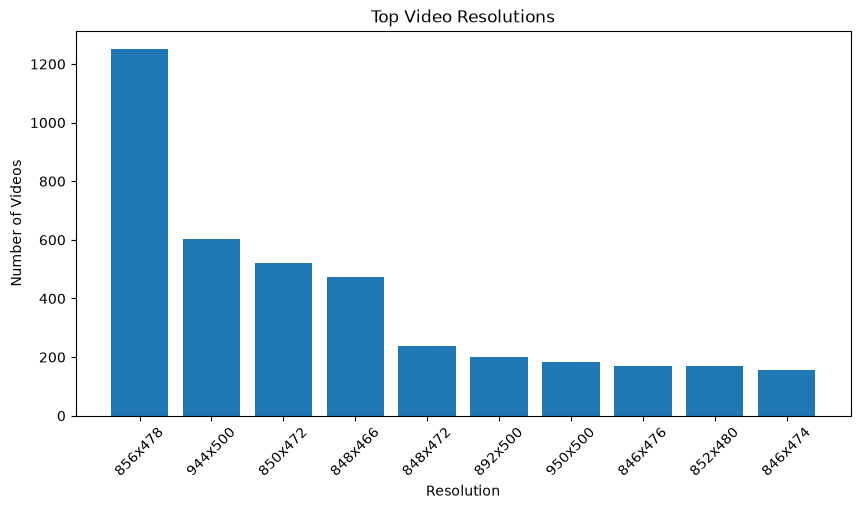

In [139]:
top_resolutions = resolution_counts.head(10)

plt.figure(figsize=(10, 5))

plt.bar(
    top_resolutions.index,
    top_resolutions.values
)

plt.title("Top Video Resolutions")
plt.xlabel("Resolution")
plt.ylabel("Number of Videos")

plt.xticks(rotation=45)

plt.show()

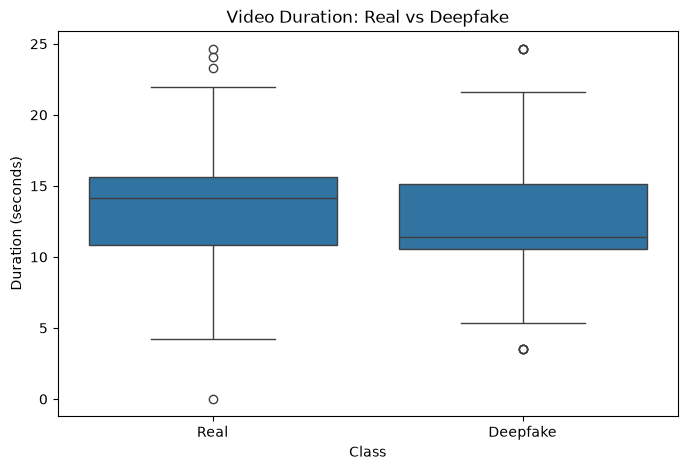

In [140]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=video_metadata_df[
        video_metadata_df["label"].isin([0, 1])
    ],
    x="class_name",
    y="duration"
)

plt.title("Video Duration: Real vs Deepfake")
plt.xlabel("Class")
plt.ylabel("Duration (seconds)")

plt.show()

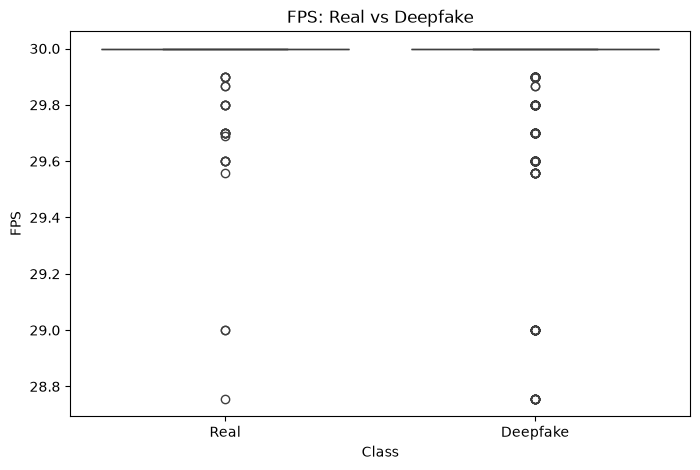

In [141]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=video_metadata_df[
        video_metadata_df["label"].isin([0, 1])
    ],
    x="class_name",
    y="fps"
)

plt.title("FPS: Real vs Deepfake")
plt.xlabel("Class")
plt.ylabel("FPS")

plt.show()

In [142]:
invalid_fps = video_metadata_df[
    video_metadata_df["fps"] <= 0
]

print("Invalid FPS videos:", len(invalid_fps))

Invalid FPS videos: 0


In [143]:
zero_frame_videos = video_metadata_df[
    video_metadata_df["frame_count"] <= 0
]

print("Videos with zero frames:", len(zero_frame_videos))

Videos with zero frames: 0


In [144]:
short_videos = video_metadata_df[
    video_metadata_df["duration"] < 1
]

print("Videos shorter than 1 second:", len(short_videos))

Videos shorter than 1 second: 1


In [145]:
print("Missing values:")
print(video_metadata_df.isnull().sum())

Missing values:
video_path     0
filename       0
folder         0
fps            0
frame_count    0
width          0
height         0
duration       0
label          0
class_name     0
resolution     0
dtype: int64


In [146]:
duplicate_filenames = (
    video_metadata_df["filename"]
    .duplicated()
    .sum()
)

print(
    "Duplicate filenames:",
    duplicate_filenames
)

Duplicate filenames: 0


In [147]:
#save meta data

RESULTS_DIR = PROJECT_ROOT / "results"

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

metadata_path = RESULTS_DIR / "video_metadata.csv"

video_metadata_df.to_csv(
    metadata_path,
    index=False
)

print("Metadata saved at:")
print(metadata_path)

Metadata saved at:
..\results\video_metadata.csv


In [148]:
print("=" * 50)
print("DAY 2 — DATASET EDA SUMMARY")
print("=" * 50)

print("Total videos:", len(video_metadata_df))

print(
    "Real videos:",
    (video_metadata_df["label"] == 0).sum()
)

print(
    "Deepfake videos:",
    (video_metadata_df["label"] == 1).sum()
)

print(
    "Unknown videos:",
    (video_metadata_df["label"] == -1).sum()
)

print(
    "Invalid FPS:",
    (video_metadata_df["fps"] <= 0).sum()
)

print(
    "Zero-frame videos:",
    (video_metadata_df["frame_count"] <= 0).sum()
)

print(
    "Videos shorter than 1 second:",
    (video_metadata_df["duration"] < 1).sum()
)

print(
    "Missing values:",
    video_metadata_df.isnull().sum().sum()
)

print("=" * 50)

DAY 2 — DATASET EDA SUMMARY
Total videos: 6529
Real videos: 890
Deepfake videos: 5639
Unknown videos: 0
Invalid FPS: 0
Zero-frame videos: 0
Videos shorter than 1 second: 1
Missing values: 0


# DAY 3 data cleaning

In [149]:
print("Total records:", len(video_metadata_df))

display(video_metadata_df.head())

Total records: 6529


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name,resolution
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333,0,Real,942x500
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000,0,Real,942x500
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667,0,Real,942x500
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333,0,Real,942x500
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667,0,Real,942x500


In [150]:
missing_values = video_metadata_df.isnull().sum()

print("Missing values in each column:")
display(missing_values)

missing_percentage = (
    video_metadata_df.isnull().mean() * 100
).round(2)

missing_df = pd.DataFrame({
    "Missing_Count": missing_values,
    "Missing_Percentage": missing_percentage
})

display(missing_df)

Missing values in each column:


video_path     0
filename       0
folder         0
fps            0
frame_count    0
width          0
height         0
duration       0
label          0
class_name     0
resolution     0
dtype: int64

,Missing_Count,Missing_Percentage
video_path,0,0.0
filename,0,0.0
folder,0,0.0
fps,0,0.0
frame_count,0,0.0
width,0,0.0
height,0,0.0
duration,0,0.0
label,0,0.0
class_name,0,0.0


In [151]:
duplicate_rows = video_metadata_df.duplicated().sum()

print("Duplicate rows:", duplicate_rows)

Duplicate rows: 0


In [152]:
duplicate_paths = video_metadata_df["video_path"].duplicated().sum()

print("Duplicate video paths:", duplicate_paths)

Duplicate video paths: 0


In [153]:
invalid_fps = video_metadata_df[
    (video_metadata_df["fps"] <= 0) |
    (video_metadata_df["fps"].isna())
]

print("Videos with invalid FPS:", len(invalid_fps))

display(invalid_fps.head())

Videos with invalid FPS: 0


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name,resolution


In [154]:
invalid_frames = video_metadata_df[
    (video_metadata_df["frame_count"] <= 0) |
    (video_metadata_df["frame_count"].isna())
]

print(
    "Videos with invalid frame count:",
    len(invalid_frames)
)

Videos with invalid frame count: 0


In [155]:
invalid_duration = video_metadata_df[
    (video_metadata_df["duration"] <= 0) |
    (video_metadata_df["duration"].isna())
]

print(
    "Videos with invalid duration:",
    len(invalid_duration)
)

Videos with invalid duration: 0


In [156]:
invalid_resolution = video_metadata_df[
    (video_metadata_df["width"] <= 0) |
    (video_metadata_df["height"] <= 0)
]

print(
    "Videos with invalid resolution:",
    len(invalid_resolution)
)

Videos with invalid resolution: 0


In [157]:
# check samll video 
very_short = video_metadata_df[
    video_metadata_df["duration"] < 1
]

print(
    "Videos shorter than 1 second:",
    len(very_short)
)

Videos shorter than 1 second: 1


In [158]:
# check unusal FPS
fps_summary = (
    video_metadata_df["fps"]
    .value_counts()
    .sort_index()
)

display(fps_summary.head(20))

fps
28.756999    10
29.000008     9
29.000014     8
29.558997     9
29.599987     8
29.599988    10
29.599991    10
29.599995     9
29.690013     1
29.699997     8
29.700000     1
29.700001    10
29.700004     1
29.700017     5
29.700018     5
29.799997     8
29.800002     8
29.800006     1
29.800011     9
29.867995     3
Name: count, dtype: int64

In [159]:
display(fps_summary.tail(20))

fps
29.599991      10
29.599995       9
29.690013       1
29.699997       8
29.700000       1
29.700001      10
29.700004       1
29.700017       5
29.700018       5
29.799997       8
29.800002       8
29.800006       1
29.800011       9
29.867995       3
29.868001       1
29.899991      10
29.899993      10
29.900003       9
29.900009       9
30.000000    6357
Name: count, dtype: int64

In [160]:
# check resolution
resolution_summary = (
    video_metadata_df[
        ["width", "height"]
    ]
    .value_counts()
    .reset_index(name="count")
)

display(resolution_summary.head(20))

,width,height,count
0,856.0,478.0,1251
1,944.0,500.0,604
2,850.0,472.0,520
3,848.0,466.0,475
4,848.0,472.0,239
5,892.0,500.0,199
6,950.0,500.0,183
7,846.0,476.0,169
8,852.0,480.0,169
9,846.0,474.0,156


In [161]:
# video validation 
#Haan, error ka reason simple hai: assign_label() function Day 1 me define nahi hua tha, isliye Day 2 me Python usko recognize nahi kar raha.

unreadable_videos = []

for i, video_path in enumerate(video_metadata_df["video_path"]):

    cap = cv2.VideoCapture(video_path)

    if not cap.isOpened():
        unreadable_videos.append(video_path)
    else:
        ret, frame = cap.read()

        if not ret or frame is None:
            unreadable_videos.append(video_path)

    cap.release()

    if (i + 1) % 100 == 0:
        print(
            f"Checked {i + 1}/{len(video_metadata_df)} videos"
        )

print(
    "Unreadable/corrupted videos:",
    len(unreadable_videos)
)

Checked 100/6529 videos
Checked 200/6529 videos
Checked 300/6529 videos
Checked 400/6529 videos
Checked 500/6529 videos
Checked 600/6529 videos
Checked 700/6529 videos
Checked 800/6529 videos
Checked 900/6529 videos
Checked 1000/6529 videos
Checked 1100/6529 videos
Checked 1200/6529 videos
Checked 1300/6529 videos
Checked 1400/6529 videos
Checked 1500/6529 videos
Checked 1600/6529 videos
Checked 1700/6529 videos
Checked 1800/6529 videos
Checked 1900/6529 videos
Checked 2000/6529 videos
Checked 2100/6529 videos
Checked 2200/6529 videos
Checked 2300/6529 videos
Checked 2400/6529 videos
Checked 2500/6529 videos
Checked 2600/6529 videos
Checked 2700/6529 videos
Checked 2800/6529 videos
Checked 2900/6529 videos
Checked 3000/6529 videos
Checked 3100/6529 videos
Checked 3200/6529 videos
Checked 3300/6529 videos
Checked 3400/6529 videos
Checked 3500/6529 videos
Checked 3600/6529 videos
Checked 3700/6529 videos
Checked 3800/6529 videos
Checked 3900/6529 videos
Checked 4000/6529 videos
Checked 4

In [162]:
corrupt_df = pd.DataFrame({
    "video_path": unreadable_videos
})

corrupt_path = RESULTS_DIR / "unreadable_videos.csv"

corrupt_df.to_csv(
    corrupt_path,
    index=False
)

print("Saved:", corrupt_path)

Saved: ..\results\unreadable_videos.csv


In [163]:
# create cleaning report 

cleaning_report = {
    "total_videos": len(video_metadata_df),
    "missing_values": int(video_metadata_df.isnull().sum().sum()),
    "duplicate_rows": int(video_metadata_df.duplicated().sum()),
    "duplicate_paths": int(
        video_metadata_df["video_path"].duplicated().sum()
    ),
    "invalid_fps": len(invalid_fps),
    "invalid_frame_count": len(invalid_frames),
    "invalid_duration": len(invalid_duration),
    "invalid_resolution": len(invalid_resolution),
    "very_short_videos": len(very_short),
    "unreadable_videos": len(unreadable_videos)
}

cleaning_report_df = pd.DataFrame(
    list(cleaning_report.items()),
    columns=["Check", "Count"]
)

display(cleaning_report_df)

,Check,Count
0,total_videos,6529
1,missing_values,0
2,duplicate_rows,0
3,duplicate_paths,0
4,invalid_fps,0
5,invalid_frame_count,0
6,invalid_duration,0
7,invalid_resolution,0
8,very_short_videos,1
9,unreadable_videos,0


In [164]:
# decide which record need removal 

invalid_mask = (
    (video_metadata_df["fps"] <= 0) |
    (video_metadata_df["frame_count"] <= 0) |
    (video_metadata_df["duration"] <= 0) |
    (video_metadata_df["width"] <= 0) |
    (video_metadata_df["height"] <= 0)
)

print("Clearly invalid metadata records:", invalid_mask.sum())


Clearly invalid metadata records: 0


In [165]:
cleaned_metadata_df = video_metadata_df[
    ~invalid_mask
].copy()

print("Original records:", len(video_metadata_df))
print("Cleaned records:", len(cleaned_metadata_df))
print(
    "Removed records:",
    len(video_metadata_df) - len(cleaned_metadata_df)
)

Original records: 6529
Cleaned records: 6529
Removed records: 0


In [166]:
# remove unreadable videos
if len(unreadable_videos) > 0:

    cleaned_metadata_df = cleaned_metadata_df[
        ~cleaned_metadata_df["video_path"].isin(
            unreadable_videos
        )
    ].copy()

print(
    "Final records after removing unreadable videos:",
    len(cleaned_metadata_df)
)

Final records after removing unreadable videos: 6529


In [167]:
print("Final missing values:")
print(cleaned_metadata_df.isnull().sum())

print("\nFinal duplicate rows:")
print(cleaned_metadata_df.duplicated().sum())

print("\nFinal total videos:")
print(len(cleaned_metadata_df))

Final missing values:
video_path     0
filename       0
folder         0
fps            0
frame_count    0
width          0
height         0
duration       0
label          0
class_name     0
resolution     0
dtype: int64

Final duplicate rows:
0

Final total videos:
6529


In [168]:
# check class distribution after cleaning
cleaned_metadata_df["class_name"] = (
    cleaned_metadata_df["label"].map(label_names)
)

class_after_cleaning = (
    cleaned_metadata_df["class_name"]
    .value_counts()
)

display(class_after_cleaning)


class_after_cleaning_percentage = (
    class_after_cleaning
    / class_after_cleaning.sum()
    * 100
).round(2)

display(class_after_cleaning_percentage)

class_name
Deepfake    5639
Real         890
Name: count, dtype: int64

class_name
Deepfake    86.37
Real        13.63
Name: count, dtype: float64

In [169]:
# save cleaned meta data 
cleaned_metadata_path = (
    RESULTS_DIR / "cleaned_video_metadata.csv"
)

cleaned_metadata_df.to_csv(
    cleaned_metadata_path,
    index=False
)

print(
    "Cleaned metadata saved at:",
    cleaned_metadata_path
)


Cleaned metadata saved at: ..\results\cleaned_video_metadata.csv


In [170]:
print("=" * 60)
print("DAY 3 — DATA CLEANING SUMMARY")
print("=" * 60)

print(
    "Original videos:",
    len(video_metadata_df)
)

print(
    "Final cleaned videos:",
    len(cleaned_metadata_df)
)

print(
    "Removed videos:",
    len(video_metadata_df)
    - len(cleaned_metadata_df)
)

print(
    "Missing values:",
    cleaned_metadata_df.isnull().sum().sum()
)

print(
    "Duplicate rows:",
    cleaned_metadata_df.duplicated().sum()
)

print(
    "Real videos:",
    (cleaned_metadata_df["label"] == 0).sum()
)

print(
    "Deepfake videos:",
    (cleaned_metadata_df["label"] == 1).sum()
)

print("=" * 60)

DAY 3 — DATA CLEANING SUMMARY
Original videos: 6529
Final cleaned videos: 6529
Removed videos: 0
Missing values: 0
Duplicate rows: 0
Real videos: 890
Deepfake videos: 5639


#  DAY 4 — Frame Sampling and Visualization

Objectives:
- Sample multiple frames from videos
- Visualize frames at different timestamps
- Compare Real and Deepfake videos
- Inspect frame quality
- Identify suitable frame sampling strategy

In [171]:
print("Total cleaned videos:", len(cleaned_metadata_df))

display(cleaned_metadata_df.head())

Total cleaned videos: 6529


,video_path,filename,folder,fps,frame_count,width,height,duration,label,class_name,resolution
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000.mp4,Celeb-real,30.0,469.0,942.0,500.0,15.633333,0,Real,942x500
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001.mp4,Celeb-real,30.0,303.0,942.0,500.0,10.100000,0,Real,942x500
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002.mp4,Celeb-real,30.0,350.0,942.0,500.0,11.666667,0,Real,942x500
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003.mp4,Celeb-real,30.0,529.0,942.0,500.0,17.633333,0,Real,942x500
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004.mp4,Celeb-real,30.0,326.0,942.0,500.0,10.866667,0,Real,942x500


In [172]:
# function to sample frame 
def sample_video_frames(video_path, num_frames=5):
    
    cap = cv2.VideoCapture(str(video_path))
    
    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )
    
    if total_frames <= 0:
        cap.release()
        return []
    
    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )
    
    frames = []
    
    for index in frame_indices:
        
        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(index)
        )
        
        ret, frame = cap.read()
        
        if ret:
            
            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )
            
            frames.append(
                (index, frame)
            )
    
    cap.release()
    
    return frames



In [173]:
# test  on 1 video

sample_path = cleaned_metadata_df.iloc[0]["video_path"]

frames = sample_video_frames(
    sample_path,
    num_frames=5
)

print("Frames extracted:", len(frames))

Frames extracted: 5


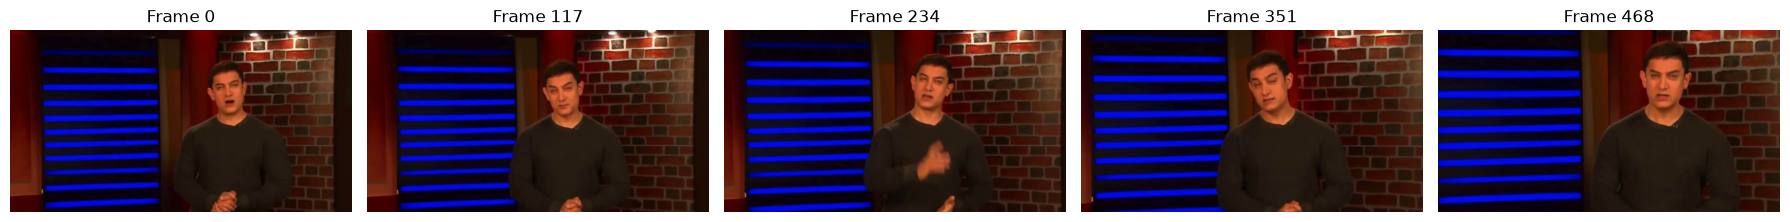

In [174]:
# display sampled frames
fig, axes = plt.subplots(
    1,
    len(frames),
    figsize=(18, 4)
)

for ax, (frame_number, frame) in zip(
    axes,
    frames
):
    
    ax.imshow(frame)
    
    ax.set_title(
        f"Frame {frame_number}"
    )
    
    ax.axis("off")

plt.tight_layout()
plt.show()


In [175]:
# Find  1 real video
real_videos = cleaned_metadata_df[
    cleaned_metadata_df["label"] == 0
]

print("Real videos:", len(real_videos))

real_video_path = real_videos.iloc[0]["video_path"]

print(real_video_path)


Real videos: 890
..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4


In [176]:
# sample from real video
real_frames = sample_video_frames(
    real_video_path,
    num_frames=5
)

print(
    "Real video frames:",
    len(real_frames)
)

Real video frames: 5


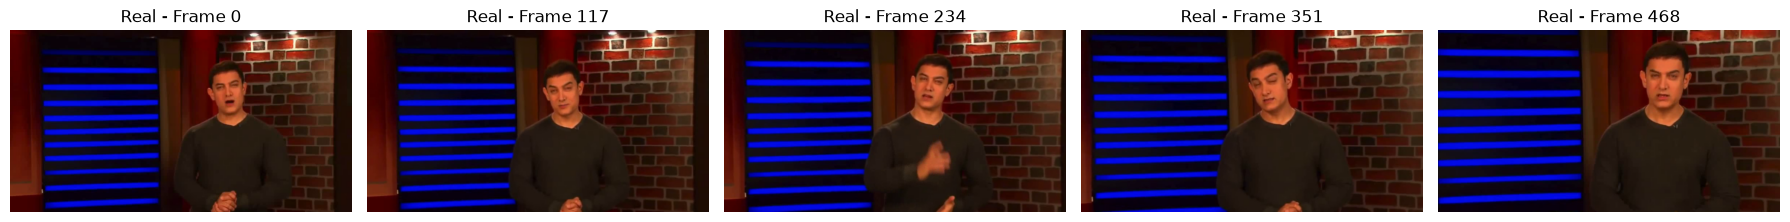

In [177]:
# display real video frames

fig, axes = plt.subplots(
    1,
    len(real_frames),
    figsize=(18, 4)
)

for ax, (frame_number, frame) in zip(
    axes,
    real_frames
):
    
    ax.imshow(frame)
    
    ax.set_title(
        f"Real - Frame {frame_number}"
    )
    
    ax.axis("off")

plt.tight_layout()
plt.show()

In [178]:
# 1 deepfake frame 
fake_videos = cleaned_metadata_df[
    cleaned_metadata_df["label"] == 1
]

print("Deepfake videos:", len(fake_videos))

fake_video_path = fake_videos.iloc[0]["video_path"]

print(fake_video_path)

Deepfake videos: 5639
..\datasets\Celeb-DF-v2\Celeb-synthesis\id0_id16_0000.mp4


In [179]:
# sample deepfake 

fake_frames = sample_video_frames(
    fake_video_path,
    num_frames=5
)

print(
    "Deepfake video frames:",
    len(fake_frames)
)

Deepfake video frames: 5


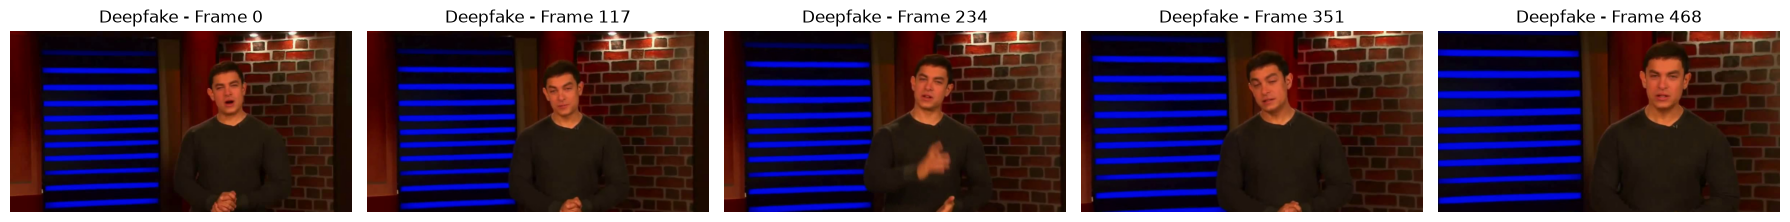

In [180]:
fig, axes = plt.subplots(
    1,
    len(fake_frames),
    figsize=(18, 4)
)

for ax, (frame_number, frame) in zip(
    axes,
    fake_frames
):
    
    ax.imshow(frame)
    
    ax.set_title(
        f"Deepfake - Frame {frame_number}"
    )
    
    ax.axis("off")

plt.tight_layout()
plt.show()

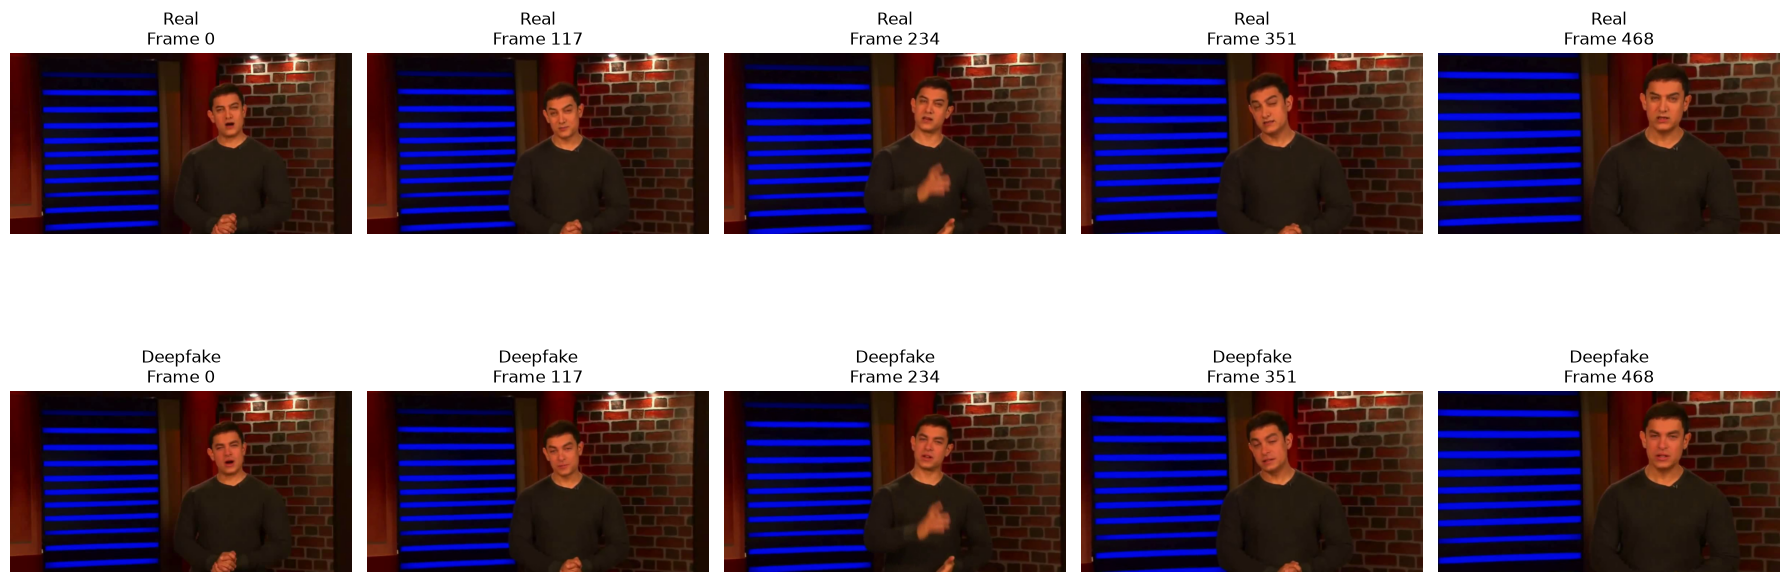

In [181]:
# real vs deepfake comparison 
fig, axes = plt.subplots(
    2,
    5,
    figsize=(18, 8)
)

for i, (frame_number, frame) in enumerate(real_frames):
    
    axes[0, i].imshow(frame)
    axes[0, i].set_title(
        f"Real\nFrame {frame_number}"
    )
    axes[0, i].axis("off")


for i, (frame_number, frame) in enumerate(fake_frames):
    
    axes[1, i].imshow(frame)
    axes[1, i].set_title(
        f"Deepfake\nFrame {frame_number}"
    )
    axes[1, i].axis("off")


plt.tight_layout()
plt.show()

In [182]:
# check different video

real_samples = real_videos.sample(
    n=min(3, len(real_videos)),
    random_state=42
)

fake_samples = fake_videos.sample(
    n=min(3, len(fake_videos)),
    random_state=42
)

print("Selected Real videos:")
display(real_samples[["filename", "video_path"]])

print("\nSelected Deepfake videos:")
display(fake_samples[["filename", "video_path"]])

Selected Real videos:


,filename,video_path
280,id37_0001.mp4,..\datasets\Celeb-DF-v2\Celeb-real\id37_0001.mp4
434,id51_0004.mp4,..\datasets\Celeb-DF-v2\Celeb-real\id51_0004.mp4
39,id13_0001.mp4,..\datasets\Celeb-DF-v2\Celeb-real\id13_0001.mp4



Selected Deepfake videos:


,filename,video_path
2714,id29_id30_0005.mp4,..\datasets\Celeb-DF-v2\Celeb-synthesis\id29_i...
2199,id26_id19_0003.mp4,..\datasets\Celeb-DF-v2\Celeb-synthesis\id26_i...
4083,id39_id42_0000.mp4,..\datasets\Celeb-DF-v2\Celeb-synthesis\id39_i...


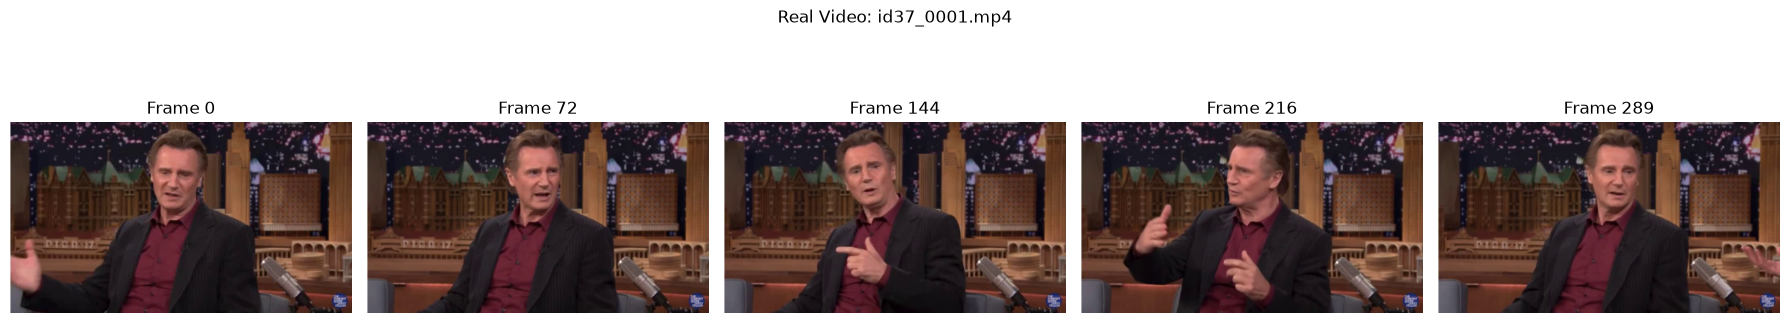

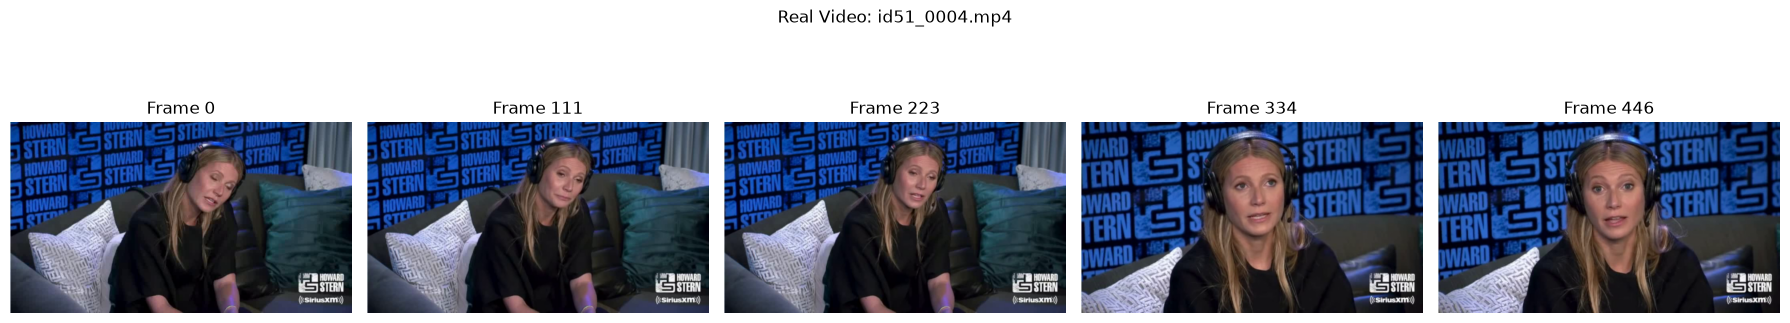

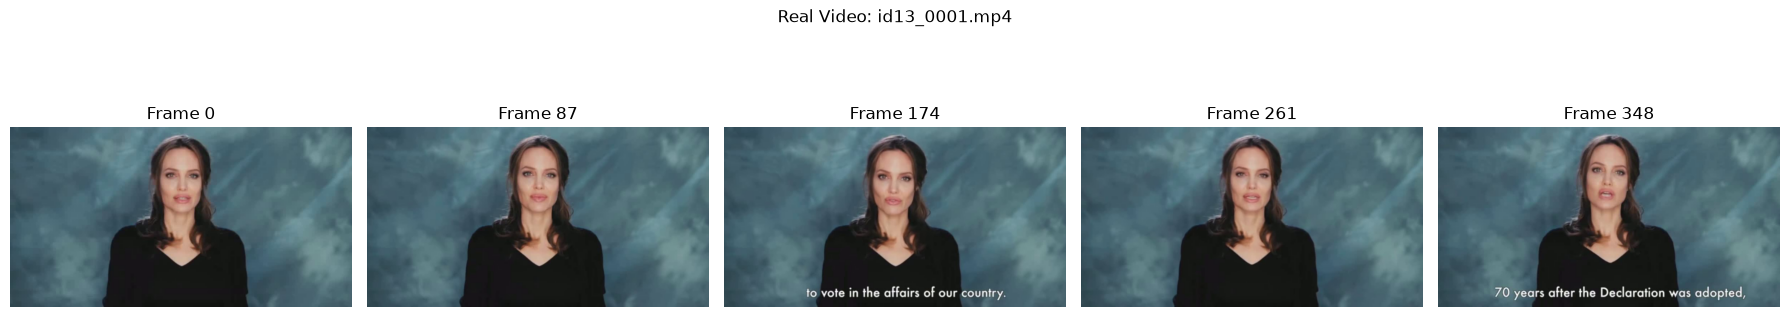

In [183]:
# multiple real video visualize

for _, row in real_samples.iterrows():

    frames = sample_video_frames(
        row["video_path"],
        num_frames=5
    )

    fig, axes = plt.subplots(
        1,
        len(frames),
        figsize=(18, 4)
    )

    for ax, (frame_number, frame) in zip(
        axes,
        frames
    ):
        
        ax.imshow(frame)
        ax.set_title(
            f"Frame {frame_number}"
        )
        ax.axis("off")

    plt.suptitle(
        f"Real Video: {row['filename']}"
    )

    plt.tight_layout()
    plt.show()

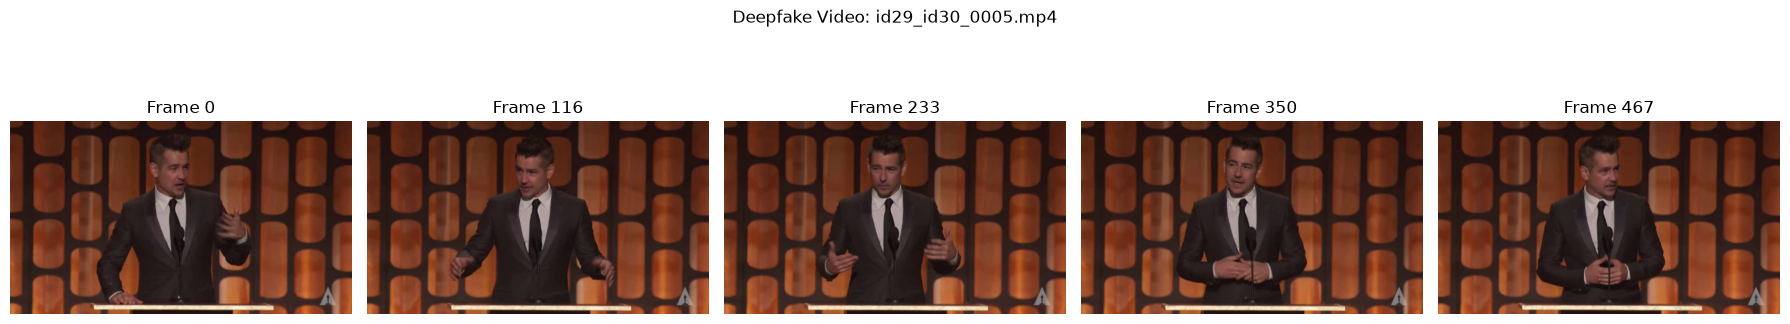

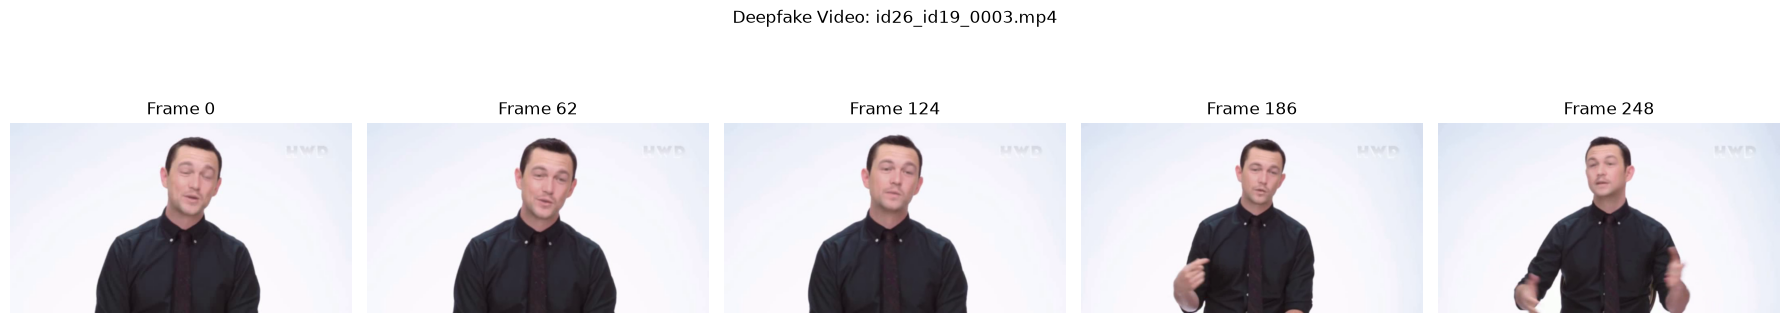

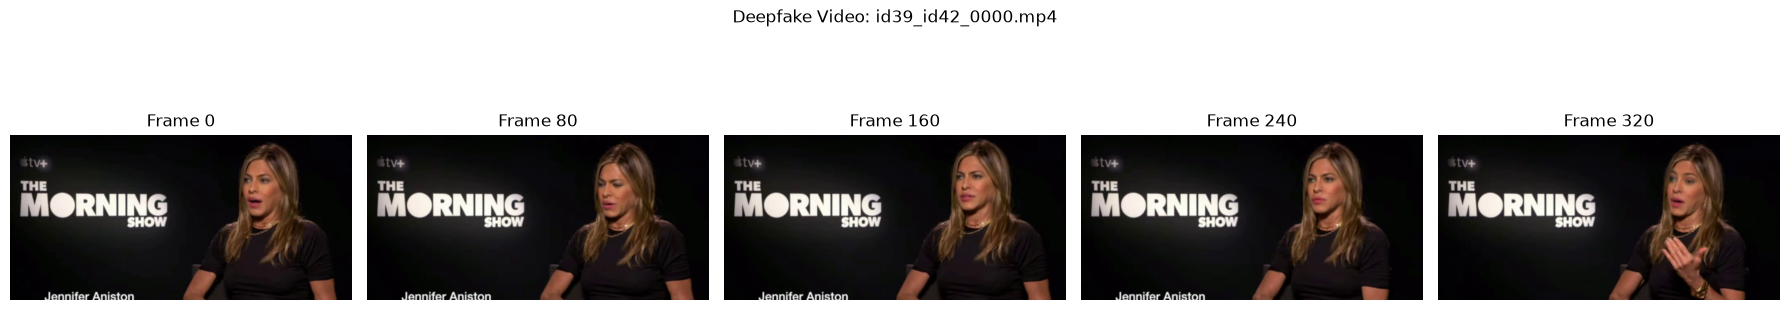

In [184]:
# multiple fake sample 

for _, row in fake_samples.iterrows():

    frames = sample_video_frames(
        row["video_path"],
        num_frames=5
    )

    fig, axes = plt.subplots(
        1,
        len(frames),
        figsize=(18, 4)
    )

    for ax, (frame_number, frame) in zip(
        axes,
        frames
    ):
        
        ax.imshow(frame)
        ax.set_title(
            f"Frame {frame_number}"
        )
        ax.axis("off")

    plt.suptitle(
        f"Deepfake Video: {row['filename']}"
    )

    plt.tight_layout()
    plt.show()

In [185]:
# Frame quality check
def frame_quality(frame):
    
    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_RGB2GRAY
    )
    
    brightness = np.mean(gray)
    
    sharpness = cv2.Laplacian(
        gray,
        cv2.CV_64F
    ).var()
    
    return brightness, sharpness

In [186]:
#test frame quality

brightness, sharpness = frame_quality(
    real_frames[0][1]
)

print("Brightness:", round(brightness, 2))
print("Sharpness:", round(sharpness, 2))

Brightness: 29.48
Sharpness: 25.06


In [187]:
# save samole image 
SAMPLE_DIR = RESULTS_DIR / "sample_frames"

SAMPLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Sample frame directory:")
print(SAMPLE_DIR)

#real frame

real_frame_path = SAMPLE_DIR / "real_sample.jpg"

plt.imsave(
    real_frame_path,
    real_frames[0][1]
)

print("Saved:", real_frame_path)

# deepfake frame
fake_frame_path = SAMPLE_DIR / "deepfake_sample.jpg"

plt.imsave(
    fake_frame_path,
    fake_frames[0][1]
)

print("Saved:", fake_frame_path)


Sample frame directory:
..\results\sample_frames
Saved: ..\results\sample_frames\real_sample.jpg
Saved: ..\results\sample_frames\deepfake_sample.jpg


In [188]:
#5 uniformly sampled frames per video for exploratory analysis.

# DAY 5 — Face Detection and Face Cropping

Objectives:
- Detect faces from sampled video frames
- Crop detected face regions
- Visualize detected faces
- Compare face detection on Real and Deepfake videos
- Prepare the foundation for face-based deepfake detection

In [189]:
#face detection libary

import mediapipe as mp

print("MediaPipe imported successfully!")

MediaPipe imported successfully!


In [190]:
# initialize  face detector 

import cv2
import os


print("OpenCV version:", cv2.__version__)
print("OpenCV location:", cv2.__file__)
print("cv2.data:", cv2.data.haarcascades)

print(
    "Cascade folder exists:",
    os.path.exists(cv2.data.haarcascades)
)

print(
    "Cascade XML exists:",
    os.path.exists(
        cv2.data.haarcascades
        + "haarcascade_frontalface_default.xml"
    )
)


import urllib.request
import os

cascade_url = (
    "https://raw.githubusercontent.com/"
    "opencv/opencv/master/data/haarcascades/"
    "haarcascade_frontalface_default.xml"
)

cascade_file = "haarcascade_frontalface_default.xml"

urllib.request.urlretrieve(
    cascade_url,
    cascade_file
)

print(
    "Downloaded:",
    os.path.exists(cascade_file)
)

face_cascade = cv2.CascadeClassifier(
    "haarcascade_frontalface_default.xml"
)

print(
    "Face detector loaded:",
    not face_cascade.empty()
)

OpenCV version: 5.0.0
OpenCV location: C:\Users\Raja Kumar\AppData\Roaming\Python\Python311\site-packages\cv2\__init__.py
cv2.data: C:\Users\Raja Kumar\AppData\Roaming\Python\Python311\site-packages\cv2\data\
Cascade folder exists: True
Cascade XML exists: False
Downloaded: True
Face detector loaded: True


In [191]:
# create face detection function 

def detect_faces(frame):
    
    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_RGB2GRAY
    )
    
    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.1,
        minNeighbors=5,
        minSize=(50, 50)
    )
    
    return faces

In [192]:
# test on real frame
test_real_frame = real_frames[0][1]

faces = detect_faces(test_real_frame)

print("Faces detected:", len(faces))
print("Face coordinates:", faces)

Faces detected: 1
Face coordinates: [[545 112 106 106]]


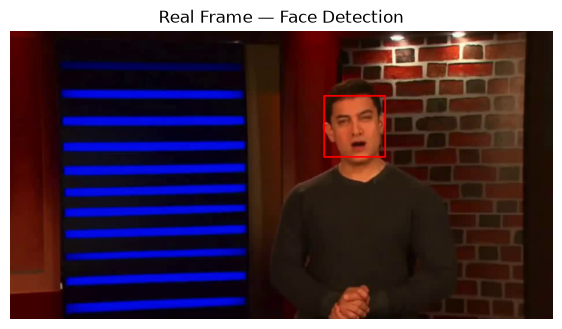

In [193]:
# draw bounding  box
frame_with_faces = test_real_frame.copy()

for (x, y, w, h) in faces:
    
    cv2.rectangle(
        frame_with_faces,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

plt.figure(figsize=(7, 5))

plt.imshow(frame_with_faces)
plt.title("Real Frame — Face Detection")
plt.axis("off")

plt.show()

In [194]:
# Detect face in Deepfake frame
test_fake_frame = fake_frames[0][1]

fake_faces = detect_faces(test_fake_frame)

print("Faces detected:", len(fake_faces))
print("Face coordinates:", fake_faces)

Faces detected: 1
Face coordinates: [[548 113 104 104]]


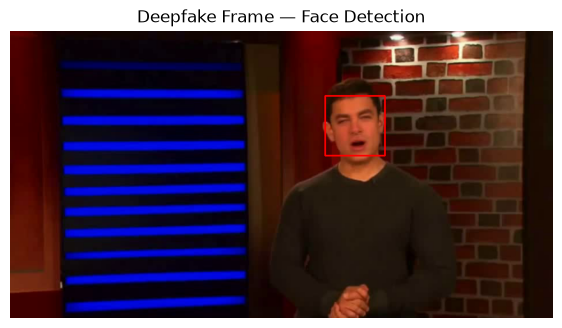

In [195]:
# visualize deepfake detection
fake_frame_with_faces = test_fake_frame.copy()

for (x, y, w, h) in fake_faces:
    
    cv2.rectangle(
        fake_frame_with_faces,
        (x, y),
        (x + w, y + h),
        (255, 0, 0),
        2
    )

plt.figure(figsize=(7, 5))

plt.imshow(fake_frame_with_faces)
plt.title("Deepfake Frame — Face Detection")
plt.axis("off")

plt.show()

In [196]:
# creat face cropping function
def crop_faces(frame):
    
    faces = detect_faces(frame)
    
    face_crops = []
    
    for (x, y, w, h) in faces:
        
        face = frame[
            y:y+h,
            x:x+w
        ]
        
        if face.size > 0:
            face_crops.append(face)
    
    return face_crops


In [197]:
# test face cropping
real_face_crops = crop_faces(
    test_real_frame
)

print(
    "Real faces cropped:",
    len(real_face_crops)
)

Real faces cropped: 1


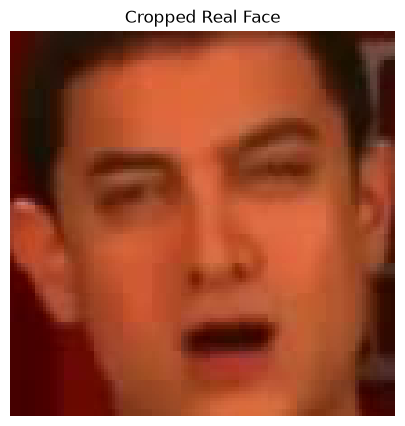

In [198]:
# dsiplay cropped real face

if len(real_face_crops) > 0:
    
    plt.figure(figsize=(5, 5))
    
    plt.imshow(
        real_face_crops[0]
    )
    
    plt.title("Cropped Real Face")
    plt.axis("off")
    
    plt.show()

else:
    print("No face detected.")

In [199]:
fake_face_crops = crop_faces(
    test_fake_frame
)

print(
    "Deepfake faces cropped:",
    len(fake_face_crops)
)

Deepfake faces cropped: 1


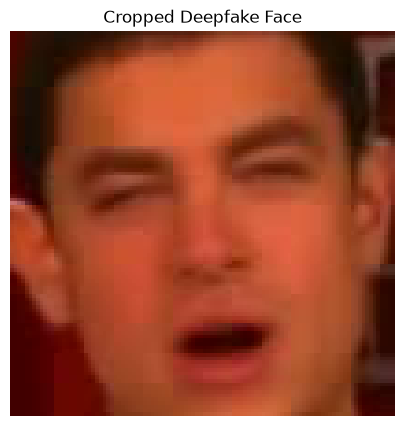

In [200]:
# display deepfake face

if len(fake_face_crops) > 0:
    
    plt.figure(figsize=(5, 5))
    
    plt.imshow(
        fake_face_crops[0]
    )
    
    plt.title("Cropped Deepfake Face")
    plt.axis("off")
    
    plt.show()

else:
    print("No face detected.")

In [201]:
# adding padding around face 

def crop_face_with_padding(
    frame,
    box,
    padding=0.2
):
    
    x, y, w, h = box
    
    pad_x = int(w * padding)
    pad_y = int(h * padding)
    
    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)
    
    x2 = min(
        frame.shape[1],
        x + w + pad_x
    )
    
    y2 = min(
        frame.shape[0],
        y + h + pad_y
    )
    
    face = frame[
        y1:y2,
        x1:x2
    ]
    
    return face

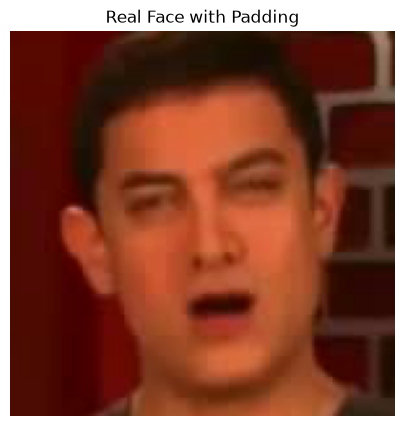

In [202]:
# test padded face

if len(faces) > 0:
    
    padded_face = crop_face_with_padding(
        test_real_frame,
        faces[0],
        padding=0.2
    )
    
    plt.figure(figsize=(5, 5))
    
    plt.imshow(padded_face)
    
    plt.title(
        "Real Face with Padding"
    )
    
    plt.axis("off")
    
    plt.show()

In [203]:
# resize face 
TARGET_SIZE = (224, 224)

resized_face = cv2.resize(
    padded_face,
    TARGET_SIZE
)

print(
    "Original face shape:",
    padded_face.shape
)

print(
    "Resized face shape:",
    resized_face.shape
)

Original face shape: (148, 148, 3)
Resized face shape: (224, 224, 3)


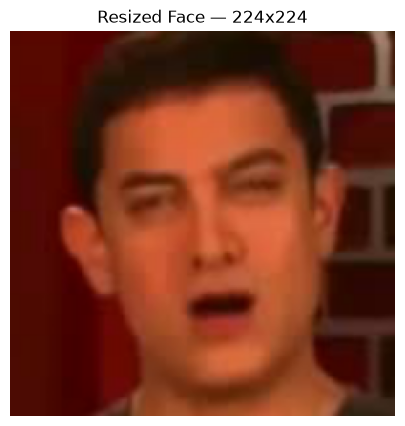

In [204]:
# visualise resized face 

plt.figure(figsize=(5,5))
plt.imshow(resized_face)

plt.title("Resized Face — 224x224")

plt.axis("off")

plt.show()

In [205]:
#Test detection across 5 Real frames
real_detection_results = []

for frame_number, frame in real_frames:
    
    faces = detect_faces(frame)
    
    real_detection_results.append({
        "frame_number": frame_number,
        "faces_detected": len(faces)
    })

real_detection_df = pd.DataFrame(
    real_detection_results
)

display(real_detection_df)


,frame_number,faces_detected
0,0,1
1,117,1
2,234,1
3,351,1
4,468,1


In [206]:
# test detction across 5 deepfake frame 
fake_detection_results = []

for frame_number, frame in fake_frames:
    
    faces = detect_faces(frame)
    
    fake_detection_results.append({
        "frame_number": frame_number,
        "faces_detected": len(faces)
    })

fake_detection_df = pd.DataFrame(
    fake_detection_results
)

display(fake_detection_df)

,frame_number,faces_detected
0,0,1
1,117,1
2,234,1
3,351,1
4,468,1


In [207]:
# calculate detction rate 

real_detection_rate = (
    (real_detection_df["faces_detected"] > 0).mean()
    * 100
)

fake_detection_rate = (
    (fake_detection_df["faces_detected"] > 0).mean()
    * 100
)

print(
    f"Real face detection rate: "
    f"{real_detection_rate:.2f}%"
)

print(
    f"Deepfake face detection rate: "
    f"{fake_detection_rate:.2f}%"
)

#Ye model accuracy nahi hai.

#Ye sirf:

#sampled frames me face detector kitni baar face detect kar raha hai

#iska measurement hai.




Real face detection rate: 100.00%
Deepfake face detection rate: 100.00%


In [208]:
# save sampled cropped faces
FACE_SAMPLE_DIR = (
    RESULTS_DIR / "face_samples"
)

FACE_SAMPLE_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print(FACE_SAMPLE_DIR)

# REAL
if len(real_face_crops) > 0:
    
    real_face_path = (
        FACE_SAMPLE_DIR /
        "real_face.jpg"
    )
    
    plt.imsave(
        real_face_path,
        real_face_crops[0]
    )
    
    print(
        "Saved:",
        real_face_path
    )

# deepfake 
if len(fake_face_crops) > 0:
    
    fake_face_path = (
        FACE_SAMPLE_DIR /
        "deepfake_face.jpg"
    )
    
    plt.imsave(
        fake_face_path,
        fake_face_crops[0]
    )
    
    print(
        "Saved:",
        fake_face_path
    )



..\results\face_samples
Saved: ..\results\face_samples\real_face.jpg
Saved: ..\results\face_samples\deepfake_face.jpg


# DAY 6 — Large-Scale Face Extraction and Preprocessing

Objectives:
- Extract multiple frames from each video
- Detect faces from sampled frames
- Crop the detected face
- Add padding around the face
- Resize faces to 224x224
- Save processed face images
- Create a frame-level metadata file

In [209]:
import os
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from pathlib import Path
from tqdm.auto import tqdm

In [210]:
# create output directories 

PROCESSED_DIR = Path("results/processed_faces")

REAL_DIR = PROCESSED_DIR / "real"
FAKE_DIR = PROCESSED_DIR / "deepfake"

REAL_DIR.mkdir(parents=True, exist_ok=True)
FAKE_DIR.mkdir(parents=True, exist_ok=True)

print("Processed face directories created.")
print("Real:", REAL_DIR)
print("Deepfake:", FAKE_DIR)

Processed face directories created.
Real: results\processed_faces\real
Deepfake: results\processed_faces\deepfake


In [211]:
# final face detection function 

def detect_faces(frame):

    gray = cv2.cvtColor(
        frame,
        cv2.COLOR_RGB2GRAY
    )

    faces = face_cascade.detectMultiScale(
        gray,
        scaleFactor=1.05,
        minNeighbors=3,
        minSize=(30, 30)
    )

    return faces

In [212]:
# face crop with padding 
def crop_face_with_padding(
    frame,
    box,
    padding=0.20
):

    x, y, w, h = box

    pad_x = int(w * padding)
    pad_y = int(h * padding)

    x1 = max(0, x - pad_x)
    y1 = max(0, y - pad_y)

    x2 = min(
        frame.shape[1],
        x + w + pad_x
    )

    y2 = min(
        frame.shape[0],
        y + h + pad_y
    )

    face = frame[y1:y2, x1:x2]

    return face

In [213]:
# frame sampling function
def get_sampled_frames(
    video_path,
    num_frames=10
):

    cap = cv2.VideoCapture(str(video_path))

    total_frames = int(
        cap.get(cv2.CAP_PROP_FRAME_COUNT)
    )

    if total_frames <= 0:
        cap.release()
        return []

    frame_indices = np.linspace(
        0,
        total_frames - 1,
        num_frames,
        dtype=int
    )

    frames = []

    for frame_index in frame_indices:

        cap.set(
            cv2.CAP_PROP_POS_FRAMES,
            int(frame_index)
        )

        ret, frame = cap.read()

        if ret and frame is not None:

            frame = cv2.cvtColor(
                frame,
                cv2.COLOR_BGR2RGB
            )

            frames.append(
                (int(frame_index), frame)
            )

    cap.release()

    return frames

In [214]:
# test complete pipeline on 1 video
test_video_path = cleaned_metadata_df.iloc[0]["video_path"]

test_frames = get_sampled_frames(
    test_video_path,
    num_frames=10
)

print("Video:", test_video_path)
print("Frames sampled:", len(test_frames))

Video: ..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4
Frames sampled: 10


In [215]:
# extract face from test video
test_faces = []

for frame_number, frame in test_frames:

    faces = detect_faces(frame)

    if len(faces) > 0:

        # Select the largest detected face
        largest_face = max(
            faces,
            key=lambda box: box[2] * box[3]
        )

        face = crop_face_with_padding(
            frame,
            largest_face,
            padding=0.20
        )

        if face.size > 0:

            face = cv2.resize(
                face,
                (224, 224)
            )

            test_faces.append(
                (frame_number, face)
            )

print("Faces successfully extracted:", len(test_faces))

Faces successfully extracted: 10


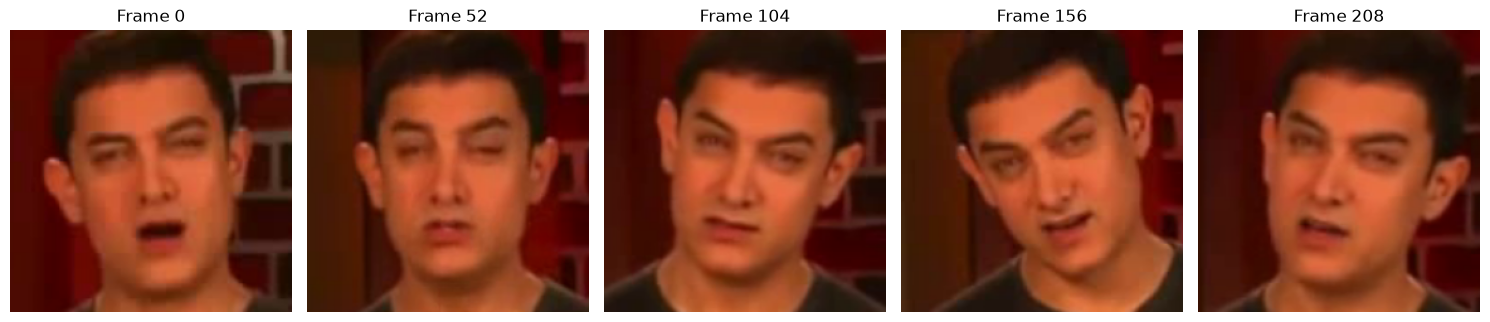

In [216]:
# visualize extracted faces
if len(test_faces) > 0:

    display_count = min(
        5,
        len(test_faces)
    )

    fig, axes = plt.subplots(
        1,
        display_count,
        figsize=(15, 4)
    )

    if display_count == 1:
        axes = [axes]

    for ax, (frame_number, face) in zip(
        axes,
        test_faces[:display_count]
    ):

        ax.imshow(face)
        ax.set_title(
            f"Frame {frame_number}"
        )
        ax.axis("off")

    plt.tight_layout()
    plt.show()

else:

    print("No face was detected in the sampled frames.")


In [217]:
# create extractionn function 
# poore dataset ke liye 
def extract_faces_from_video(
    video_path,
    num_frames=10,
    target_size=(224, 224),
    padding=0.20
):

    sampled_frames = get_sampled_frames(
        video_path,
        num_frames=num_frames
    )

    extracted_faces = []

    for frame_number, frame in sampled_frames:

        faces = detect_faces(frame)

        if len(faces) == 0:
            continue

        largest_face = max(
            faces,
            key=lambda box: box[2] * box[3]
        )

        face = crop_face_with_padding(
            frame,
            largest_face,
            padding=padding
        )

        if face.size == 0:
            continue

        face = cv2.resize(
            face,
            target_size
        )

        extracted_faces.append(
            (frame_number, face)
        )

    return extracted_faces

In [218]:
# test function again

test_result = extract_faces_from_video(
    test_video_path,
    num_frames=10
)

print(
    "Successfully extracted faces:",
    len(test_result)
)

Successfully extracted faces: 10


In [227]:
# Full dataset extraction
FRAMES_PER_VIDEO = 10

extraction_records = []

for index, row in tqdm(
    cleaned_metadata_df.iterrows(),
    total=len(cleaned_metadata_df),
    desc="Extracting faces"
):

    video_path = row["video_path"]
    label = int(row["label"])
    class_name = row["class_name"]

    faces = extract_faces_from_video(
        video_path,
        num_frames=FRAMES_PER_VIDEO,
        target_size=(224, 224),
        padding=0.20
    )

    for frame_number, face in faces:

        if label == 0:
            output_dir = REAL_DIR
        else:
            output_dir = FAKE_DIR

        video_stem = Path(
            video_path
        ).stem

        image_name = (
            f"{video_stem}_"
            f"frame_{frame_number}.jpg"
        )

        image_path = (
            output_dir / image_name
        )

        # Convert RGB back to BGR for OpenCV saving
        face_bgr = cv2.cvtColor(
            face,
            cv2.COLOR_RGB2BGR
        )

        cv2.imwrite(
            str(image_path),
            face_bgr
        )

        extraction_records.append({
            "video_path": str(video_path),
            "video_name": video_stem,
            "frame_number": frame_number,
            "image_path": str(image_path),
            "label": label,
            "class_name": class_name
        })

print(
    "Total extracted faces:",
    len(extraction_records)
)

Extracting faces:   0%|          | 0/6529 [00:00<?, ?it/s]

Total extracted faces: 65084


In [228]:
# create frame metadata

frame_metadata_df = pd.DataFrame(
    extraction_records
)
display(
    frame_metadata_df.head()
)


print(
    "Total face images:",
    len(frame_metadata_df)
)

print(
    "Unique videos:",
    frame_metadata_df["video_name"].nunique()
)

,video_path,video_name,frame_number,image_path,label,class_name
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,0,results\processed_faces\real\id0_0000_frame_0.jpg,0,Real
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,52,results\processed_faces\real\id0_0000_frame_52...,0,Real
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,104,results\processed_faces\real\id0_0000_frame_10...,0,Real
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,156,results\processed_faces\real\id0_0000_frame_15...,0,Real
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,208,results\processed_faces\real\id0_0000_frame_20...,0,Real


Total face images: 65084
Unique videos: 6528


In [229]:
# clss distribution
print("Face images by class:")

display(
    frame_metadata_df["class_name"].value_counts()
)

Face images by class:


class_name
Deepfake    56258
Real         8826
Name: count, dtype: int64

In [230]:
# save meta data
frame_metadata_path = (
    RESULTS_DIR / "frame_metadata.csv"
)

frame_metadata_df.to_csv(
    frame_metadata_path,
    index=False
)

print(
    "Frame metadata saved at:",
    frame_metadata_path
)


Frame metadata saved at: ..\results\frame_metadata.csv


In [231]:
# final check 
print("=" * 60)
print("DAY 6 — FACE EXTRACTION SUMMARY")
print("=" * 60)

print(
    "Videos processed:",
    cleaned_metadata_df["video_path"].nunique()
)

print(
    "Face images extracted:",
    len(frame_metadata_df)
)

print(
    "Unique videos with faces:",
    frame_metadata_df["video_name"].nunique()
)

print(
    "\nClass distribution:"
)

print(
    frame_metadata_df["class_name"]
    .value_counts()
)

print("=" * 60)

DAY 6 — FACE EXTRACTION SUMMARY
Videos processed: 6529
Face images extracted: 65084
Unique videos with faces: 6528

Class distribution:
class_name
Deepfake    56258
Real         8826
Name: count, dtype: int64


# DAY 7 — Video-Level Train, Validation and Test Split

Objectives:
- Split data at video level
- Prevent frame-level data leakage
- Create train, validation and test sets
- Preserve class distribution
- Save split metadata

In [233]:
# check meta data
print(
    "Total extracted face images:",
    len(frame_metadata_df)
)

print(
    "Unique source videos:",
    frame_metadata_df["video_name"].nunique()
)

Total extracted face images: 65084
Unique source videos: 6528


In [234]:
# create unique video dataset

video_split_df = (
    frame_metadata_df[
        [
            "video_path",
            "video_name",
            "label",
            "class_name"
        ]
    ]
    .drop_duplicates(
        subset=["video_name"]
    )
    .reset_index(drop=True)
)

print(
    "Unique videos:",
    len(video_split_df)
)

display(video_split_df.head())

Unique videos: 6528


,video_path,video_name,label,class_name
0,..\datasets\Celeb-DF-v2\Celeb-real\id0_0000.mp4,id0_0000,0,Real
1,..\datasets\Celeb-DF-v2\Celeb-real\id0_0001.mp4,id0_0001,0,Real
2,..\datasets\Celeb-DF-v2\Celeb-real\id0_0002.mp4,id0_0002,0,Real
3,..\datasets\Celeb-DF-v2\Celeb-real\id0_0003.mp4,id0_0003,0,Real
4,..\datasets\Celeb-DF-v2\Celeb-real\id0_0004.mp4,id0_0004,0,Real


In [236]:
# check class distribution
print(
    video_split_df["class_name"]
    .value_counts()
)

# import train_test_split
#70% Train, 15% Validation , 15% Test;

from sklearn.model_selection import train_test_split
train_videos, temp_videos = train_test_split(
    video_split_df,
    test_size=0.30,
    random_state=42,
    stratify=video_split_df["label"]
)

print("training videos:", len(train_videos))
print("Temporary videos:", len(temp_videos))


class_name
Deepfake    5639
Real         889
Name: count, dtype: int64
training videos: 4569
Temporary videos: 1959


In [238]:
# Validation/Test split
validation_videos, test_videos = train_test_split(
    temp_videos,
    test_size=0.50,
    random_state=42,
    stratify=temp_videos["label"]
)


print(
    "Training videos:",
    len(train_videos)
)

print(
    "Validation videos:",
    len(validation_videos)
)

print(
    "Test videos:",
    len(test_videos)
)

Training videos: 4569
Validation videos: 979
Test videos: 980


In [239]:
# verify class distribution 
print("TRAIN")
display(
    train_videos["class_name"]
    .value_counts()
)

print("\nVALIDATION")
display(
    validation_videos["class_name"]
    .value_counts()
)

print("\nTEST")
display(
    test_videos["class_name"]
    .value_counts()
)

TRAIN


class_name
Deepfake    3947
Real         622
Name: count, dtype: int64


VALIDATION


class_name
Deepfake    846
Real        133
Name: count, dtype: int64


TEST


class_name
Deepfake    846
Real        134
Name: count, dtype: int64

In [242]:
# Add split information to frame metadata

train_video_names = set(
    train_videos["video_name"]
)

validation_video_names = set(
    validation_videos["video_name"]
)

test_video_names = set(
    test_videos["video_name"]
)



def assign_split(video_name):

    if video_name in train_video_names:
        return "train"

    elif video_name in validation_video_names:
        return "validation"

    elif video_name in test_video_names:
        return "test"

    else:
        return "unknown"

frame_metadata_df["split"] =(
    frame_metadata_df["video_name"]
    .apply(assign_split)
)

In [246]:
# check split assignment 
print(
    frame_metadata_df["split"]
    .value_counts()
)
print(
    "Unknown:",
    (
        frame_metadata_df["split"]
        == "unknown"
    ).sum()
)


split
train         45547
test           9776
validation     9761
Name: count, dtype: int64
Unknown: 0


In [248]:
# check leakage 
train_set = set(
    frame_metadata_df.loc[
        frame_metadata_df["split"] == "train",
        "video_name"
    ]
)

validation_set = set(
    frame_metadata_df.loc[
        frame_metadata_df["split"] == "validation",
        "video_name"
    ]
)

test_set = set(
    frame_metadata_df.loc[
        frame_metadata_df["split"] == "test",
        "video_name"
    ]
)




print(
    "Train ∩ Validation:",
    len(train_set & validation_set)
)

print(
    "Train ∩ Test:",
    len(train_set & test_set)
)

print(
    "Validation ∩ Test:",
    len(validation_set & test_set)
)

Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0


In [249]:
#Check number of frames per split

split_counts = pd.crosstab(
    frame_metadata_df["split"],
    frame_metadata_df["class_name"]
)

display(split_counts)

class_name,Deepfake,Real
split,,
test,8444,1332
train,39376,6171
validation,8438,1323


In [250]:
# save final split metadata
split_metadata_path = (
    RESULTS_DIR / "final_frame_metadata.csv"
)

frame_metadata_df.to_csv(
    split_metadata_path,
    index=False
)

print(
    "Final metadata saved at:",
    split_metadata_path
)

Final metadata saved at: ..\results\final_frame_metadata.csv


In [251]:
# save video split files
train_videos.to_csv(
    RESULTS_DIR / "train_videos.csv",
    index=False
)

validation_videos.to_csv(
    RESULTS_DIR / "validation_videos.csv",
    index=False
)

test_videos.to_csv(
    RESULTS_DIR / "test_videos.csv",
    index=False
)

print("Train/validation/test video lists saved.")

Train/validation/test video lists saved.


In [252]:
print("=" * 60)
print("DAY 7 — DATA SPLIT SUMMARY")
print("=" * 60)

print(
    "Total unique videos:",
    len(video_split_df)
)

print(
    "Training videos:",
    len(train_videos)
)

print(
    "Validation videos:",
    len(validation_videos)
)

print(
    "Test videos:",
    len(test_videos)
)

print("\nFrame distribution:")

display(
    frame_metadata_df["split"]
    .value_counts()
)

print("\nClass distribution by split:")

display(
    pd.crosstab(
        frame_metadata_df["split"],
        frame_metadata_df["class_name"]
    )
)

print("\nLeakage check:")

print(
    "Train ∩ Validation:",
    len(train_set & validation_set)
)

print(
    "Train ∩ Test:",
    len(train_set & test_set)
)

print(
    "Validation ∩ Test:",
    len(validation_set & test_set)
)

print("=" * 60)

DAY 7 — DATA SPLIT SUMMARY
Total unique videos: 6528
Training videos: 4569
Validation videos: 979
Test videos: 980

Frame distribution:


split
train         45547
test           9776
validation     9761
Name: count, dtype: int64


Class distribution by split:


class_name,Deepfake,Real
split,,
test,8444,1332
train,39376,6171
validation,8438,1323



Leakage check:
Train ∩ Validation: 0
Train ∩ Test: 0
Validation ∩ Test: 0
